# First-order feedback: growth, decay and goal seeking in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/05-first-order.ipynb)

A first-order system has one stock and the loops that run through it. These are the only feedback systems simple enough to solve with a pencil, and their answers (doubling times, half-lives, time constants) are the rules of thumb you will use to read every bigger model. This notebook checks each rule against a simulation, shows what Euler's method gets slightly wrong, and ends with a stock whose two loops take turns to dominate.

The ideas are taught in the app module [First-order feedback: growth, decay and goal seeking](https://waelrash1.github.io/loopbricks/#/learn/first-order).

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))
import numpy as np

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. Growth: the doubling time

If a stock grows by a fixed fraction `g` of itself each year, its exact path is `S(t) = S0 × e^(g t)`, and it doubles every `ln 2 / g` years. Since ln 2 ≈ 0.69, that is about **70 divided by the growth rate in percent**: the rule of 70.

The `growth` molecule has births of 5% and deaths of 2% a year, a net growth of 3%. Let us compare the simulation with the exact formula, for several time steps.

In [2]:
g = lb.molecule("growth")
exact = 100 * np.exp(0.03 * 60)
print(f"exact population after 60 years: {exact:.1f}")
for dt in (1, 0.5, 0.1, 0.01):
    sim = g.run(dt=dt)["Population"].iloc[-1]
    print(f"Euler with dt = {dt:<4}: {sim:6.1f}  ({100 * (sim - exact) / exact:+.2f}%)")

pop = g.run()["Population"]
print(f"\nrule of 70: {70 / 3:.1f} years, exact: {np.log(2) / 0.03:.1f} years, "
      f"run passes 200 in year {pop.index[pop >= 200][0]}")

exact population after 60 years: 605.0
Euler with dt = 1   :  589.2  (-2.61%)
Euler with dt = 0.5 :  596.9  (-1.33%)
Euler with dt = 0.1 :  603.3  (-0.27%)
Euler with dt = 0.01:  604.8  (-0.03%)

rule of 70: 23.3 years, exact: 23.1 years, run passes 200 in year 23.2


Euler's method always comes out slightly low for growth, because each step uses the growth rate at the start of the step and misses the growth that happens during it. With a step of a whole year the error is 2.6%; with `dt = 0.1` it is 0.27%, small enough for most purposes. The doubling time from the run, 23.2 years, matches the exact 23.1 and the rule of 70's 23.3.

**Try it.** Raise the birth rate to 8% (keep deaths at 2%). Predict the doubling time with the rule of 70, then check it with `g.run(birth_rate=8)`.

<details><summary>Show a worked answer</summary>

The net growth is now 6%, so the rule of 70 gives 70 / 6 ≈ 11.7 years; the exact value is ln 2 / 0.06 = 11.55 years. The run passes 200 in year 11.6. Doubling the growth rate halves the doubling time.
</details>

In [3]:
fast = g.run(birth_rate=8)["Population"]
print("Population passes 200 in year", fast.index[fast >= 200][0])

Population passes 200 in year 11.6


## 2. Decay: the half-life and the time constant

When the outflow is the stock divided by a time `τ`, the stock decays exponentially: `S(t) = S0 × e^(−t/τ)`. After one time constant τ, 37% is left; the **half-life** is `τ × ln 2 ≈ 0.7 τ`.

The **Go To Zero** molecule (`goToZero`) puts two stocks side by side, both starting at 100 with τ = 5 months. One is drained in proportion to what is left; the other is drained at a constant 100 / τ = 20 a month, the rate the first one starts at.

constant action empties the stock in month 5.0
proportional action: 36.4 left after one τ, half gone in month 3.5 (exact half-life 3.47)


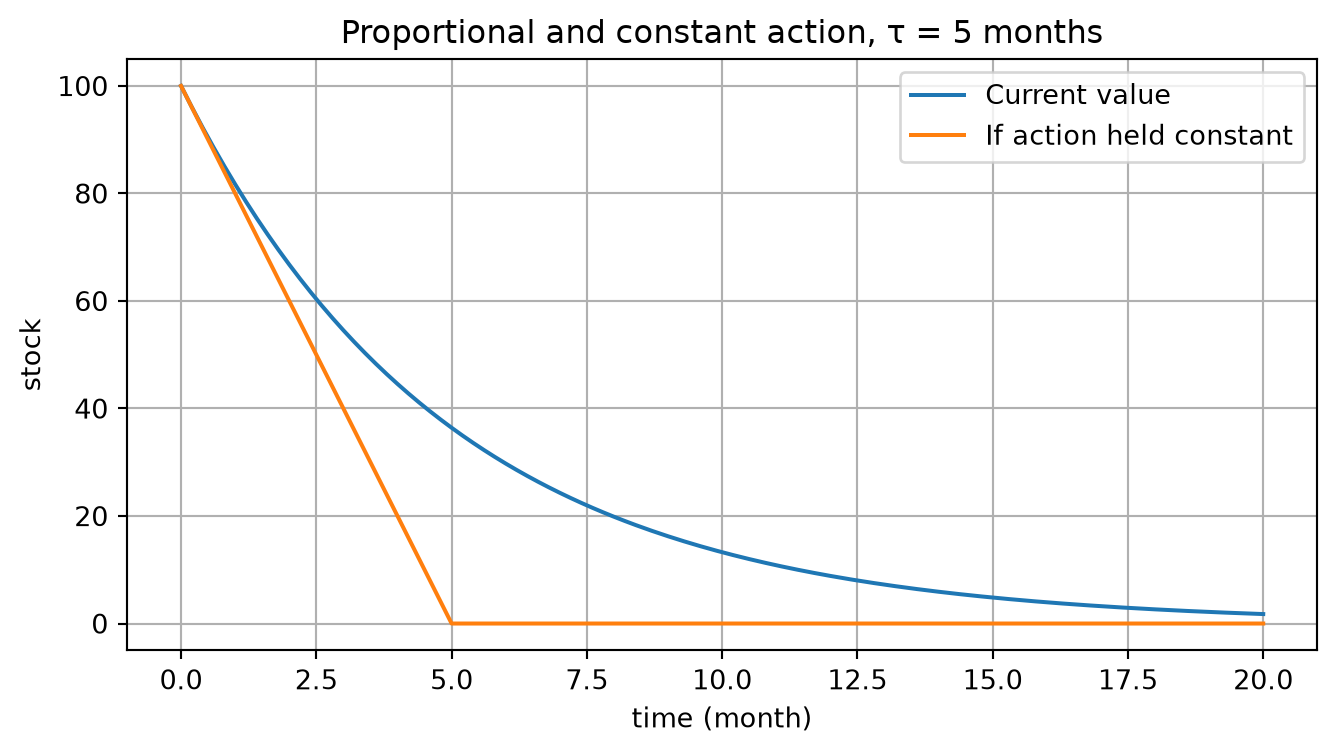

In [4]:
gz = lb.molecule("goToZero")
run = gz.run()
run[["Current value", "If action held constant"]].loc[:20].plot(figsize=(8, 4), grid=True)
plt.ylabel("stock"); plt.title("Proportional and constant action, τ = 5 months")

cur, const = run["Current value"], run["If action held constant"]
print("constant action empties the stock in month", const.index[const <= 0][0])
print(f"proportional action: {cur.loc[5.0]:.1f} left after one τ, half gone in month {cur.index[cur <= 50][0]}"
      f" (exact half-life {5 * np.log(2):.2f})")

Holding the action constant empties the stock in exactly one time constant, 5 months. Proportional action slows down as the stock shrinks, so after 5 months there is still 36.4 left (the exact value is 36.8; Euler drains slightly too fast, because each step uses the larger stock at its start), and in theory it never reaches zero. That is the meaning of the time constant: it is how long the stock would take to vanish if the flow stayed at its first value.

**Try it.** The *With replenishment* preset adds a constant inflow of 8 a month. Where does the stock settle, and why?

<details><summary>Show a worked answer</summary>

It settles where the outflow equals the inflow: stock / 5 = 8, so the stock is 8 × 5 = 40. The run ends at 40.0. In general a stock that drains in proportion to itself settles at inflow × τ, which is also the rule behind the **Residence Time** molecule: the number of people in a service equals the arrival rate times the average stay.
</details>

In [5]:
print(f"With replenishment, the stock ends at {gz.run(preset='With replenishment')['Current value'].iloc[-1]:.1f}")
res = lb.molecule("residence")
print(f"Residence Time: 8 arrivals a month x 5 months stay -> {res.run()['In service'].iloc[-1]:.1f} in service")

With replenishment, the stock ends at 40.0
Residence Time: 8 arrivals a month x 5 months stay -> 40.0 in service


## 3. Goal seeking with a drain

The **First-Order Stock Adjustment** molecule (`stockAdjust`) keeps a stock near a desired level of 100 while 10 a month is used up. Its stocking rule has two parts: close the gap over an adjustment time of 4 months, and replace what is being used (`Replacement fraction` × use). Leave out the replacement part and something surprising happens.

replacement fraction 1: level settles at 100.0
replacement fraction 0: level settles at 60.0


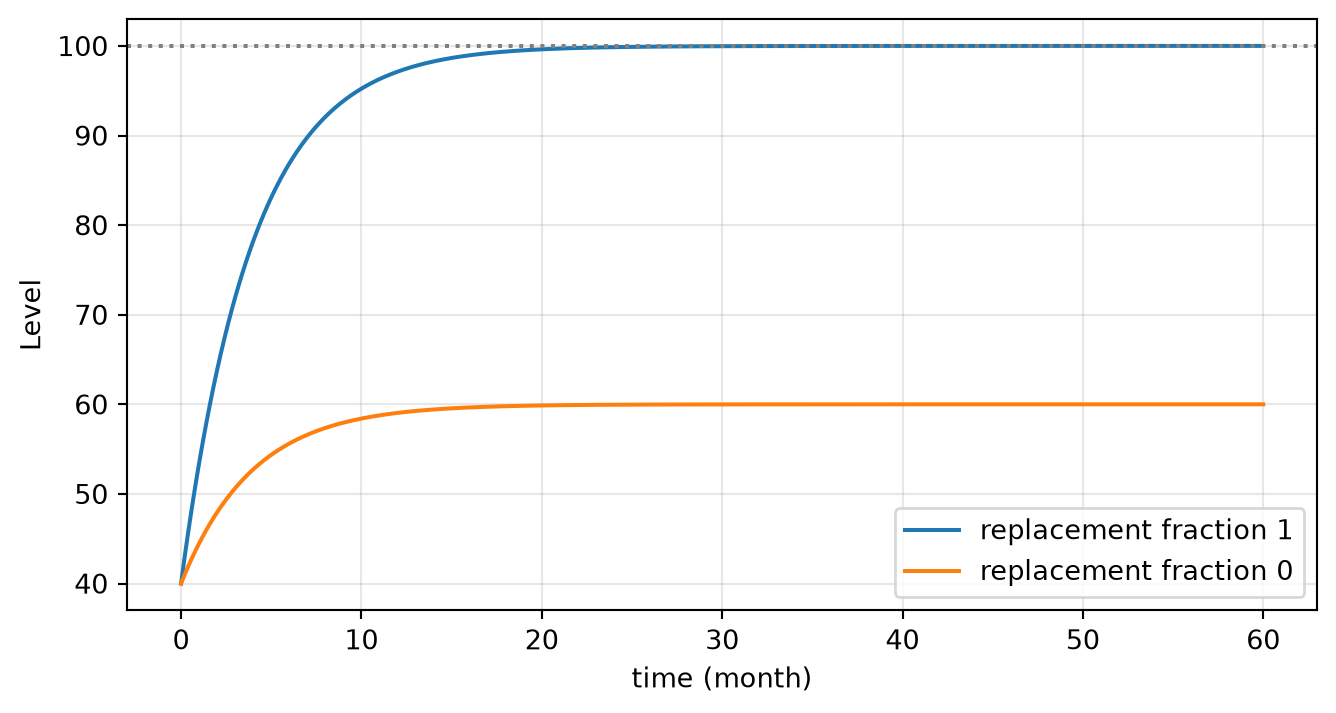

In [6]:
sa = lb.molecule("stockAdjust")
fig, ax = plt.subplots(figsize=(8, 4))
for r in (1, 0):
    sa.run(replacement_fraction=r)["Level"].plot(ax=ax, label=f"replacement fraction {r}")
ax.axhline(100, ls=":", c="grey"); ax.set_ylabel("Level"); ax.legend(); ax.grid(alpha=0.3)
for r in (1, 0):
    print(f"replacement fraction {r}: level settles at {sa.run(replacement_fraction=r)['Level'].iloc[-1]:.1f}")

Without replacement, the level settles at 60, not 100. The only thing that brings stock in is the gap, so the gap can never close: it has to stay big enough to make up for the use. In equilibrium gap / 4 = 10, so the gap is 40. This **steady-state error** equals the use rate times the adjustment time, 10 × 4 = 40, and it is why good decision rules aim at the goal *and* replace expected losses.

**Try it.** Predict the level with a replacement fraction of 0.5, then check.

<details><summary>Show a worked answer</summary>

Half the use (5 a month) is now replaced, so the gap only needs to supply the other 5: gap / 4 = 5, gap = 20, level = 80. The run settles at 80.0.
</details>

In [7]:
print(f"replacement fraction 0.5: level settles at {sa.run(replacement_fraction=0.5)['Level'].iloc[-1]:.1f}")

replacement fraction 0.5: level settles at 80.0


## 4. Two loops in one stock: shifting dominance

**Constrained Growth** (`logistic`) has one stock with a reinforcing loop (growth at 18% a year) and a balancing loop (crowding deaths that rise as the population nears its carrying capacity of 200). Because there is only one stock, the net flow depends only on the stock: `net = r × P × (1 − P / K)`. Plot the net flow against the stock and the whole behaviour is one curve.

largest net growth 9.00 a year at population 99.6, year 16.4  (theory: r K / 4 = 9.00 at K / 2 = 100)


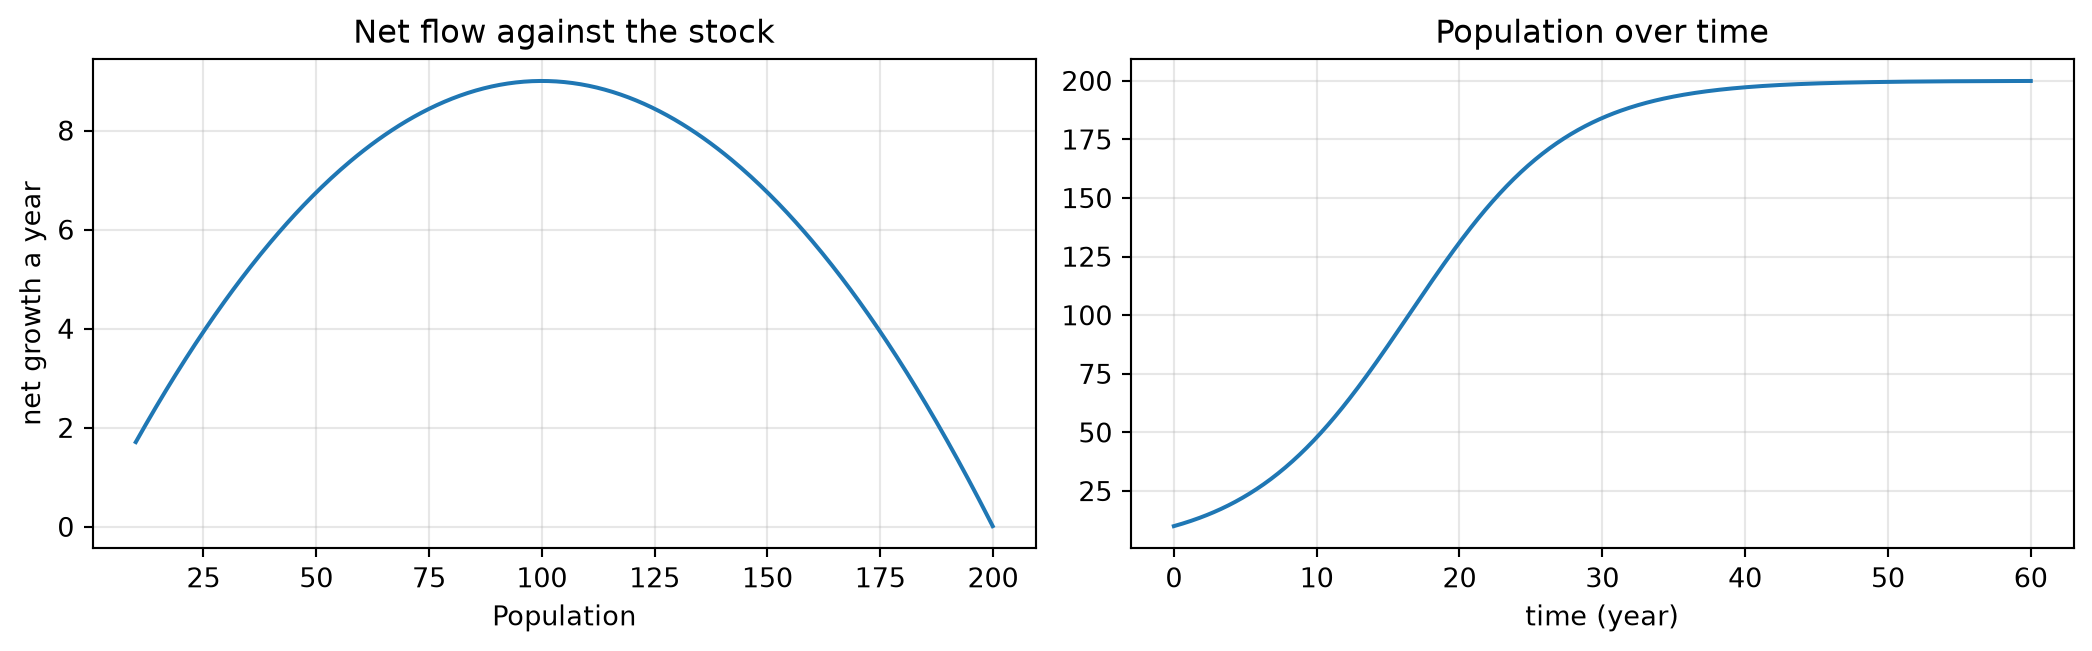

In [8]:
lg = lb.molecule("logistic")
run = lg.run()
net = run["Growth"] - run["Crowding deaths"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(run["Population"], net); a1.set_xlabel("Population"); a1.set_ylabel("net growth a year")
a1.set_title("Net flow against the stock")
run["Population"].plot(ax=a2, title="Population over time")
for ax in (a1, a2):
    ax.grid(alpha=0.3)
plt.tight_layout()

print(f"largest net growth {net.max():.2f} a year at population {run.loc[net.idxmax(), 'Population']:.1f}, "
      f"year {net.idxmax()}  (theory: r K / 4 = {0.18 * 200 / 4:.2f} at K / 2 = 100)")

The left plot is a hump. Below a population of 100, more people means more net growth: the reinforcing loop dominates and the curve bends upwards. Above 100, more people means *less* net growth: the balancing loop dominates and growth slows down until it stops at 200. The run reaches the top of the hump, 9.0 a year, in year 16.4 at a population of 99.6, just as the formula predicts. You can read off the dominant loop from the slope of this curve: rising means reinforcing, falling means balancing.

**Try it.** With the *Higher capacity* preset (K = 350), when does dominance shift? The exact solution puts the inflection point at `t = ln(K / P0 − 1) / r`, with P0 = 10 the starting population.

<details><summary>Show a worked answer</summary>

The shift happens at half the capacity, 175. The formula gives ln(350 / 10 − 1) / 0.18 = ln 34 / 0.18 ≈ 19.6 years; the run finds the largest net growth in year 19.7, at a population of 175.0. A bigger capacity gives the reinforcing loop more room, so it dominates for longer.
</details>

In [9]:
hi = lg.run(preset="Higher capacity")
net_hi = hi["Growth"] - hi["Crowding deaths"]
print(f"formula: year {np.log(350 / 10 - 1) / 0.18:.1f}; run: year {net_hi.idxmax()}, "
      f"population {hi.loc[net_hi.idxmax(), 'Population']:.1f}")

formula: year 19.6; run: year 19.7, population 175.0


## Where next

- Back in the app: the [First-order feedback](https://waelrash1.github.io/loopbricks/#/learn/first-order) module derives these results step by step.
- Section 4 is the core of [S-shaped growth: epidemics and diffusion](https://waelrash1.github.io/loopbricks/#/learn/s-shaped). What happens when a delay sits inside a balancing loop is in [Delays and perception](https://waelrash1.github.io/loopbricks/#/learn/delays), and why `dt` matters is in [Simulation mechanics](https://waelrash1.github.io/loopbricks/#/learn/mechanics).
- Earlier notebooks: [Patterns of behaviour](https://waelrash1.github.io/loopbricks/#/learn/patterns) shows these shapes from the outside; here you have seen the maths inside them.